In [ ]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn openpyxl

In [ ]:
import os
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


Upload and extract the dataset

In [ ]:
uploaded = files.upload()

zip_path = next(
    (name for name in uploaded if name.lower().endswith(".zip")),
    None
)

if zip_path is None:
    raise ValueError("Please upload the dataset as a ZIP file.")

DATA_DIR = "/content/machine_maintenance_data"
os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    # Extract only CSV files, avoiding unrelated archive contents.
    csv_members = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
        and not os.path.basename(name).startswith(".")
    ]

    for member in csv_members:
        destination = os.path.join(DATA_DIR, os.path.basename(member))

        with z.open(member) as source, open(destination, "wb") as target:
            target.write(source.read())

print("Dataset extracted successfully!")
print("Files:", sorted(os.listdir(DATA_DIR)))

Saving factory-sensors-failure-labels.zip to factory-sensors-failure-labels (1).zip
Dataset extracted successfully!
Files: ['assets.csv', 'failure_events.csv', 'sensor_readings.csv', 'sites.csv', 'work_orders.csv']


3: Load all five CSV files

In [ ]:
sites = pd.read_csv(f"{DATA_DIR}/sites.csv")
assets = pd.read_csv(f"{DATA_DIR}/assets.csv")
sensors = pd.read_csv(f"{DATA_DIR}/sensor_readings.csv")
failures = pd.read_csv(f"{DATA_DIR}/failure_events.csv")
work_orders = pd.read_csv(f"{DATA_DIR}/work_orders.csv")

datasets = {
    "Sites": sites,
    "Assets": assets,
    "Sensor Readings": sensors,
    "Failure Events": failures,
    "Work Orders": work_orders
}

for name, data in datasets.items():
    print(f"\n{name}: {data.shape[0]:,} rows, {data.shape[1]} columns")
    print(data.columns.tolist())

print("\nSensor readings preview:")
display(sensors.head())

print("\nAsset information preview:")
display(assets.head())

print("\nFailure events preview:")
display(failures.head())

print("\nWork orders preview:")
display(work_orders.head())


Sites: 1 rows, 5 columns
['site_id', 'site_name', 'site_kind', 'country', 'city']

Assets: 6 rows, 9 columns
['asset_id', 'site_id', 'asset_tag', 'asset_type', 'manufacturer', 'model_code', 'criticality', 'rated_power_kw', 'commissioned_at']

Sensor Readings: 52,560 rows, 13 columns
['reading_id', 'asset_id', 'recorded_at', 'operating_mode', 'vibration_mm_s', 'bearing_temp_c', 'motor_current_a', 'discharge_pressure_bar', 'rotor_speed_rpm', 'degradation_stage', 'rul_hours', 'failure_next_24h', 'next_failure_mode']

Failure Events: 39 rows, 7 columns
['failure_id', 'asset_id', 'failed_at', 'failure_mode', 'downtime_hours', 'restored_at', 'hours_since_last_repair']

Work Orders: 63 rows, 8 columns
['work_order_id', 'asset_id', 'order_type', 'opened_at', 'closed_at', 'labor_hours', 'parts_cost', 'priority']

Sensor readings preview:


,reading_id,asset_id,recorded_at,operating_mode,vibration_mm_s,bearing_temp_c,motor_current_a,discharge_pressure_bar,rotor_speed_rpm,degradation_stage,rul_hours,failure_next_24h,next_failure_mode
0,1,1,2025-09-01 00:00:00,idle,1.25,42.0,17.1,5.52,1476.0,healthy,603.96,False,NaN
1,2,1,2025-09-01 01:00:00,idle,1.43,40.8,16.1,5.66,1480.0,healthy,602.96,False,NaN
2,3,1,2025-09-01 02:00:00,idle,1.50,40.2,15.9,5.62,1487.0,healthy,601.96,False,NaN
3,4,1,2025-09-01 03:00:00,normal,2.12,47.8,22.5,5.54,1484.0,healthy,600.96,False,NaN
4,5,1,2025-09-01 04:00:00,normal,2.15,46.6,24.1,5.52,1487.0,healthy,599.96,False,NaN



Asset information preview:


,asset_id,site_id,asset_tag,asset_type,manufacturer,model_code,criticality,rated_power_kw,commissioned_at
0,1,1,AST-00006,Screw compressor,Ferro-Tech,MX-0006,B,20.1957,2016-12-14
1,2,1,AST-00004,Conveyor drive,Helion Machinery,MX-0004,C,21.8856,2017-10-04
2,3,1,AST-00005,Centrifugal pump,Castellan Works,MX-0005,B,17.6089,2020-02-27
3,4,1,AST-00002,Induction motor,Orsay Mechanical,MX-0002,C,18.9411,2020-04-27
4,5,1,AST-00003,Centrifugal pump,Ferro-Tech,MX-0003,B,23.9560,2023-04-12



Failure events preview:


,failure_id,asset_id,failed_at,failure_mode,downtime_hours,restored_at,hours_since_last_repair
0,1,1,2025-09-26 03:57:29,seal_leak,3.79,2025-09-26 07:44:41,872.9
1,2,4,2025-09-29 06:59:07,bearing_wear,16.70,2025-09-29 23:41:13,751.3
2,3,5,2025-10-06 06:04:03,seal_leak,4.50,2025-10-06 10:33:54,993.9
3,4,3,2025-10-16 00:13:45,bearing_wear,17.60,2025-10-16 17:50:00,1182.1
4,5,6,2025-10-17 19:35:44,bearing_wear,14.03,2025-10-18 09:37:48,1898.6



Work orders preview:


,work_order_id,asset_id,order_type,opened_at,closed_at,labor_hours,parts_cost,priority
0,1,1,corrective,2025-09-26 04:46:12,2025-09-26 07:44:41,4.6,1588.57,high
1,2,4,corrective,2025-09-29 08:45:35,2025-09-29 23:41:13,33.4,1231.69,high
2,3,4,preventive,2025-10-02 07:55:03,2025-10-02 13:19:44,8.2,94.50,planned
3,4,1,preventive,2025-10-03 15:08:39,2025-10-03 19:16:51,3.9,68.09,planned
4,5,5,corrective,2025-10-06 06:34:51,2025-10-06 10:33:54,4.9,408.83,urgent


4: Inspect data quality

In [ ]:
for name, data in datasets.items():
    print(f"\n{'=' * 50}")
    print(name.upper())

    print("\nData types:")
    print(data.dtypes)

    print("\nMissing values:")
    print(data.isnull().sum())

    print("\nDuplicate rows:", data.duplicated().sum())

print("\nSensor numerical summary:")
display(sensors.describe(include="all").T)


SITES

Data types:
site_id       int64
site_name    object
site_kind    object
country      object
city         object
dtype: object

Missing values:
site_id      0
site_name    0
site_kind    0
country      0
city         0
dtype: int64

Duplicate rows: 0

ASSETS

Data types:
asset_id             int64
site_id              int64
asset_tag           object
asset_type          object
manufacturer        object
model_code          object
criticality         object
rated_power_kw     float64
commissioned_at     object
dtype: object

Missing values:
asset_id           0
site_id            0
asset_tag          0
asset_type         0
manufacturer       0
model_code         0
criticality        0
rated_power_kw     0
commissioned_at    0
dtype: int64

Duplicate rows: 0

SENSOR READINGS

Data types:
reading_id                  int64
asset_id                    int64
recorded_at                object
operating_mode             object
vibration_mm_s            float64
bearing_temp_c            

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
reading_id,52560.0,NaN,NaN,NaN,26280.5,15172.909411,1.0,13140.75,26280.5,39420.25,52560.0
asset_id,52560.0,NaN,NaN,NaN,3.5,1.707841,1.0,2.0,3.5,5.0,6.0
recorded_at,52560,8760,2026-08-31 23:00:00,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
operating_mode,52560,4,normal,39192,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vibration_mm_s,51664.0,NaN,NaN,NaN,2.665959,1.540496,0.0,1.86,2.27,2.79,12.09
bearing_temp_c,51750.0,NaN,NaN,NaN,55.051268,13.901962,-16.5,46.0,55.0,63.7,119.5
motor_current_a,51840.0,NaN,NaN,NaN,33.163009,11.81443,0.0,25.2,34.1,41.6,87.2
discharge_pressure_bar,51990.0,NaN,NaN,NaN,6.037803,0.924184,0.0,5.79,6.18,6.53,12.94
rotor_speed_rpm,51815.0,NaN,NaN,NaN,1492.789617,172.518504,0.0,1467.0,1498.0,1533.0,3127.0
degradation_stage,52560,4,healthy,29843,NaN,NaN,NaN,NaN,NaN,NaN,NaN


5: Data preprocessing

In [ ]:
# Keep original raw data unchanged and create cleaned copies.
sites_clean = sites.drop_duplicates().copy()
assets_clean = assets.drop_duplicates().copy()
sensors_clean = sensors.drop_duplicates().copy()
failures_clean = failures.drop_duplicates().copy()
work_orders_clean = work_orders.drop_duplicates().copy()

# Convert date/time fields.
date_columns = {
    "assets": (assets_clean, ["commissioned_at"]),
    "sensors": (sensors_clean, ["recorded_at"]),
    "failures": (
        failures_clean,
        ["failed_at", "restored_at"]
    ),
    "work_orders": (
        work_orders_clean,
        ["opened_at", "closed_at"]
    )
}

for name, (data, columns) in date_columns.items():
    for col in columns:
        data[col] = pd.to_datetime(data[col], errors="coerce")

# Standardize categorical labels.
for data in [
    sites_clean, assets_clean, sensors_clean,
    failures_clean, work_orders_clean
]:
    for col in data.select_dtypes(include="object").columns:
        if col not in [
            "recorded_at", "commissioned_at",
            "failed_at", "restored_at",
            "opened_at", "closed_at"
        ]:
            data[col] = data[col].str.strip()

# Treat impossible negative measurements as missing.
# Imputation will happen inside the ML pipeline.
nonnegative_columns = [
    "vibration_mm_s",
    "motor_current_a",
    "discharge_pressure_bar",
    "rotor_speed_rpm",
    "rul_hours",
    "bearing_temp_c"
]

for col in nonnegative_columns:
    if col in sensors_clean.columns:
        invalid = sensors_clean[col] < 0
        sensors_clean.loc[invalid, col] = np.nan

# Standardize failure label to integer 0/1.
sensors_clean["failure_next_24h"] = (
    sensors_clean["failure_next_24h"]
    .astype(str).str.strip().str.lower()
    .map({
        "true": 1,
        "false": 0,
        "1": 1,
        "0": 0
    })
)

# Exclude records without the target from model training.
sensors_clean = sensors_clean.dropna(
    subset=["failure_next_24h"]
).copy()

sensors_clean["failure_next_24h"] = (
    sensors_clean["failure_next_24h"].astype(int)
)

print("Preprocessing completed.")

for name, data in {
    "Sites": sites_clean,
    "Assets": assets_clean,
    "Sensors": sensors_clean,
    "Failures": failures_clean,
    "Work Orders": work_orders_clean
}.items():
    print(
        f"{name}: {len(data):,} rows, "
        f"{data.duplicated().sum()} duplicate rows"
    )

Preprocessing completed.
Sites: 1 rows, 0 duplicate rows
Assets: 6 rows, 0 duplicate rows
Sensors: 52,560 rows, 0 duplicate rows
Failures: 39 rows, 0 duplicate rows
Work Orders: 63 rows, 0 duplicate rows


6: Merge the datasets

In [ ]:
# Join sensor readings to machine details.
analysis_df = sensors_clean.merge(
    assets_clean,
    on="asset_id",
    how="left",
    validate="many_to_one"
)

# Join site details.
analysis_df = analysis_df.merge(
    sites_clean,
    on="site_id",
    how="left",
    validate="many_to_one"
)

analysis_df["recorded_at"] = pd.to_datetime(
    analysis_df["recorded_at"], errors="coerce"
)

analysis_df["commissioned_at"] = pd.to_datetime(
    analysis_df["commissioned_at"], errors="coerce"
)

analysis_df["machine_age_years"] = (
    analysis_df["recorded_at"] -
    analysis_df["commissioned_at"]
).dt.total_seconds() / (365.25 * 24 * 60 * 60)

# Negative age indicates inconsistent dates.
analysis_df.loc[
    analysis_df["machine_age_years"] < 0,
    "machine_age_years"
] = np.nan

print("Merged dataset shape:", analysis_df.shape)
display(analysis_df.head())

Merged dataset shape: (52560, 26)


,reading_id,asset_id,recorded_at,operating_mode,vibration_mm_s,bearing_temp_c,motor_current_a,discharge_pressure_bar,rotor_speed_rpm,degradation_stage,...,manufacturer,model_code,criticality,rated_power_kw,commissioned_at,site_name,site_kind,country,city,machine_age_years
0,1,1,2025-09-01 00:00:00,idle,1.25,42.0,17.1,5.52,1476.0,healthy,...,Ferro-Tech,MX-0006,B,20.1957,2016-12-14,Jasper Works,manufacturing,United States,Chicago,8.714579
1,2,1,2025-09-01 01:00:00,idle,1.43,40.8,16.1,5.66,1480.0,healthy,...,Ferro-Tech,MX-0006,B,20.1957,2016-12-14,Jasper Works,manufacturing,United States,Chicago,8.714693
2,3,1,2025-09-01 02:00:00,idle,1.50,40.2,15.9,5.62,1487.0,healthy,...,Ferro-Tech,MX-0006,B,20.1957,2016-12-14,Jasper Works,manufacturing,United States,Chicago,8.714807
3,4,1,2025-09-01 03:00:00,normal,2.12,47.8,22.5,5.54,1484.0,healthy,...,Ferro-Tech,MX-0006,B,20.1957,2016-12-14,Jasper Works,manufacturing,United States,Chicago,8.714921
4,5,1,2025-09-01 04:00:00,normal,2.15,46.6,24.1,5.52,1487.0,healthy,...,Ferro-Tech,MX-0006,B,20.1957,2016-12-14,Jasper Works,manufacturing,United States,Chicago,8.715035


7: Exploratory Data Analysis (EDA)

7.1 Machine failure distribution

Failure distribution:
failure_next_24h
No failure within 24 hours    51663
Failure within 24 hours         897
Name: count, dtype: int64


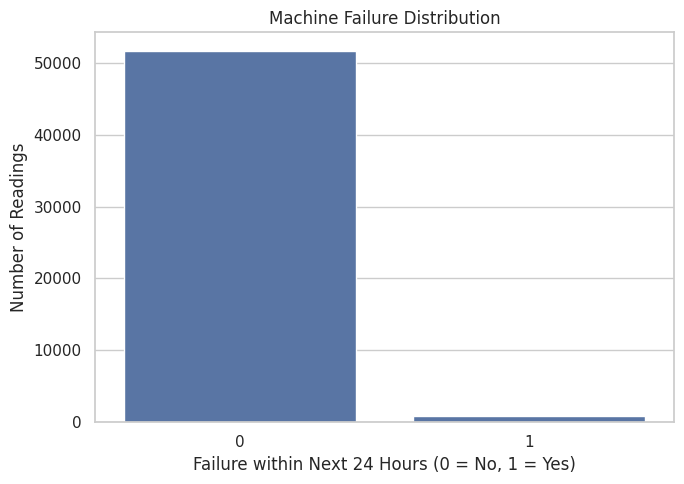

Failure percentage: 1.71 %


In [ ]:
failure_counts = (
    analysis_df["failure_next_24h"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

print("Failure distribution:")
print(failure_counts.rename({
    0: "No failure within 24 hours",
    1: "Failure within 24 hours"
}))

plt.figure(figsize=(7, 5))
sns.countplot(
    data=analysis_df,
    x="failure_next_24h"
)
plt.title("Machine Failure Distribution")
plt.xlabel("Failure within Next 24 Hours (0 = No, 1 = Yes)")
plt.ylabel("Number of Readings")
plt.tight_layout()
plt.show()

print(
    "Failure percentage:",
    round(analysis_df["failure_next_24h"].mean() * 100, 2),
    "%"
)

7.2 Sensor distributions

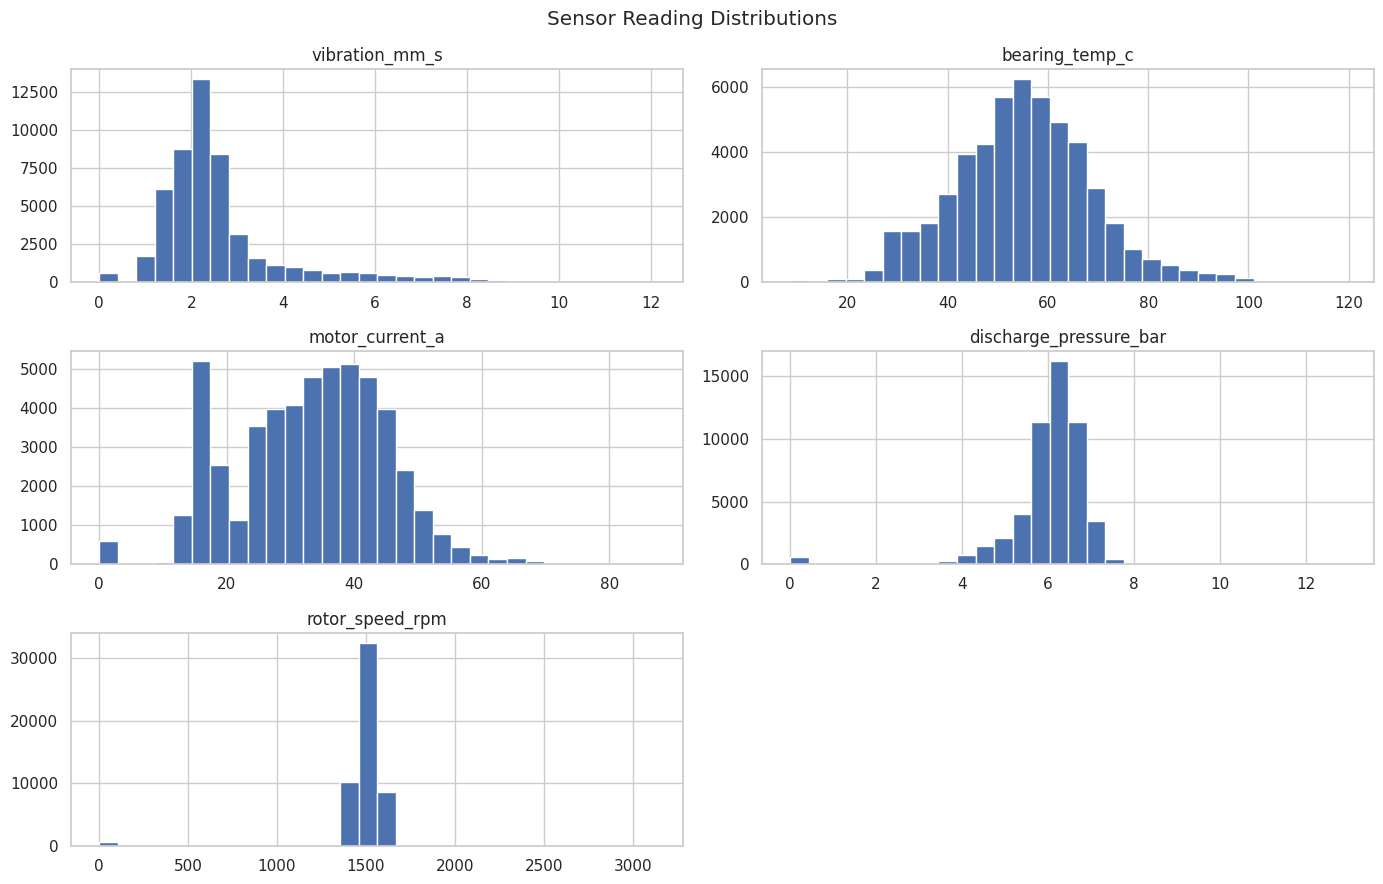

In [ ]:
sensor_columns = [
    "vibration_mm_s",
    "bearing_temp_c",
    "motor_current_a",
    "discharge_pressure_bar",
    "rotor_speed_rpm"
]

available_sensor_columns = [
    col for col in sensor_columns
    if col in analysis_df.columns
]

analysis_df[available_sensor_columns].hist(
    figsize=(14, 9),
    bins=30
)

plt.suptitle("Sensor Reading Distributions")
plt.tight_layout()
plt.show()

7.3 Sensor readings versus failures

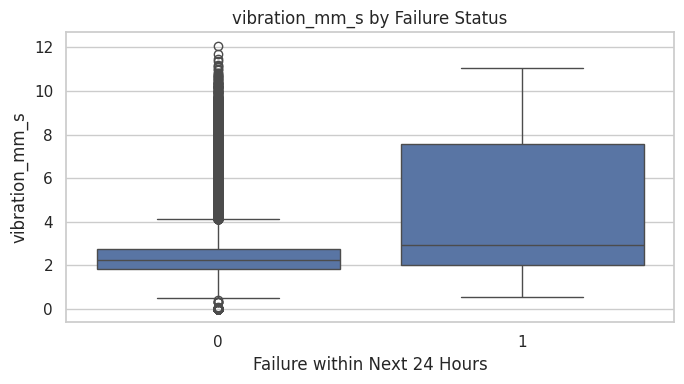

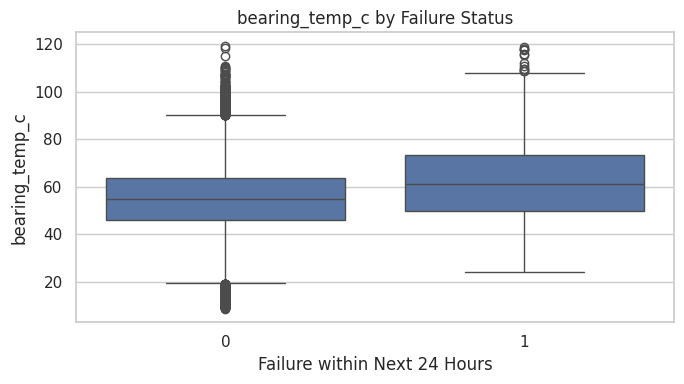

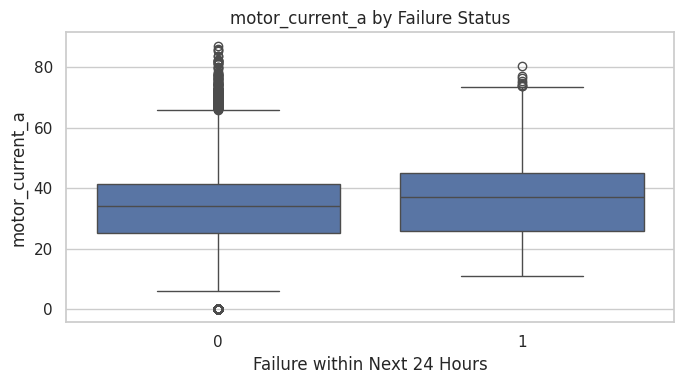

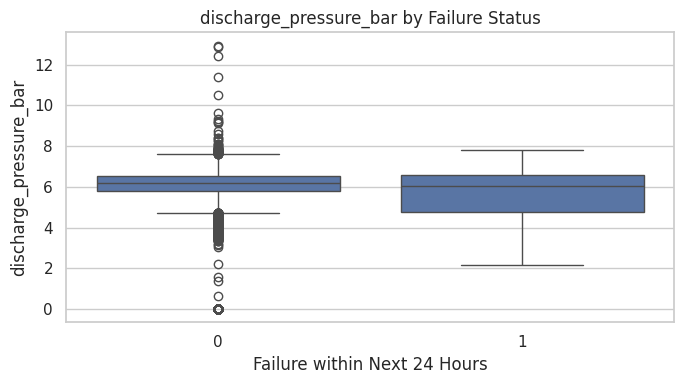

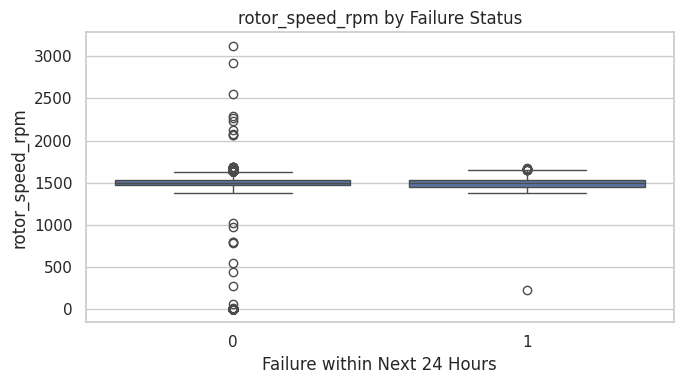

In [ ]:
for col in available_sensor_columns:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=analysis_df,
        x="failure_next_24h",
        y=col
    )

    plt.title(f"{col} by Failure Status")
    plt.xlabel("Failure within Next 24 Hours")
    plt.tight_layout()
    plt.show()

7.4 Correlation heatmap

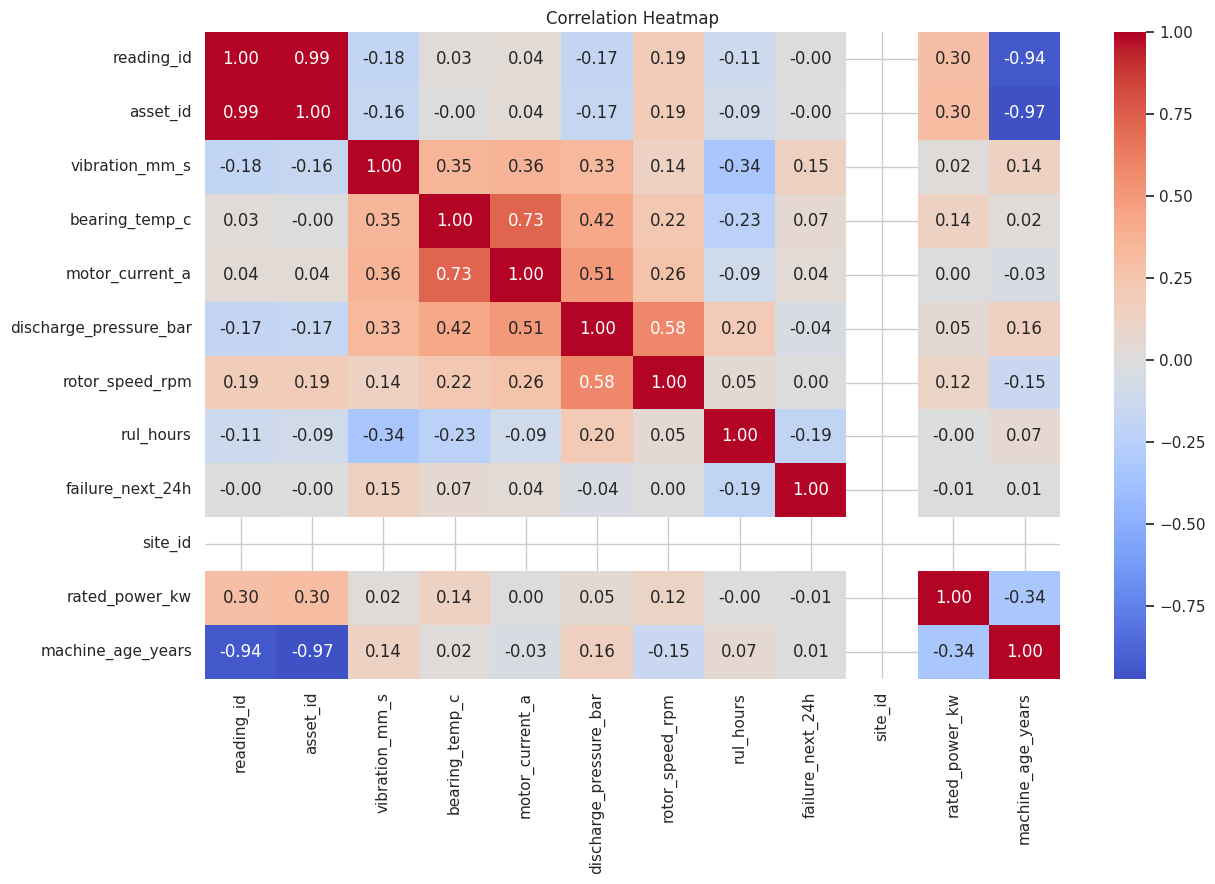

In [ ]:
numeric_df = analysis_df.select_dtypes(
    include=np.number
)

plt.figure(figsize=(13, 9))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

7.5 Failure patterns by machine type

,asset_type,total_readings,failure_readings,failure_rate,failure_rate_percent
0,Centrifugal pump,17520,299,0.017066,1.706621
1,Conveyor drive,8760,138,0.015753,1.575342
2,Induction motor,8760,207,0.023630,2.363014
3,Screw compressor,17520,253,0.014441,1.444064


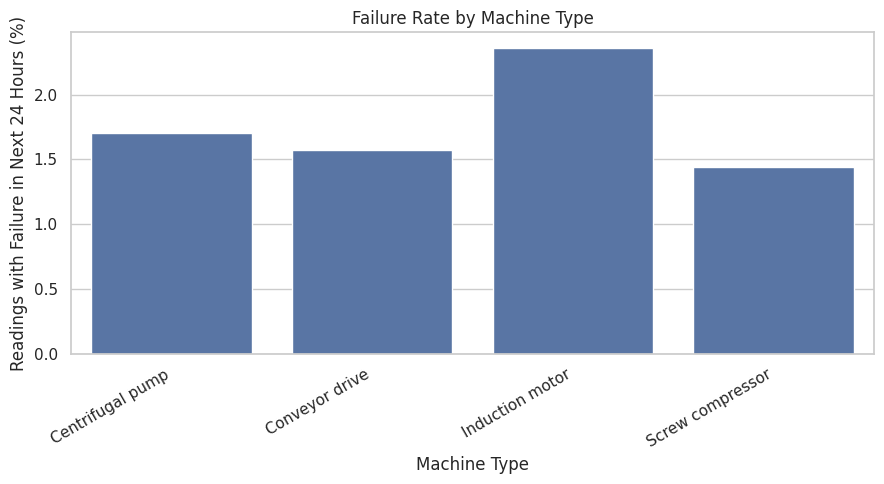

In [ ]:
machine_type_summary = (
    analysis_df.groupby("asset_type")
    .agg(
        total_readings=("failure_next_24h", "size"),
        failure_readings=("failure_next_24h", "sum"),
        failure_rate=("failure_next_24h", "mean")
    )
    .reset_index()
)

machine_type_summary["failure_rate_percent"] = (
    machine_type_summary["failure_rate"] * 100
)

display(machine_type_summary)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=machine_type_summary,
    x="asset_type",
    y="failure_rate_percent"
)

plt.title("Failure Rate by Machine Type")
plt.xlabel("Machine Type")
plt.ylabel("Readings with Failure in Next 24 Hours (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

7.6 Alarm and failure-mode frequency

,failure_mode,count
0,seal_leak,11
1,bearing_wear,11
2,electrical_fault,7
3,overheating,6
4,imbalance,4


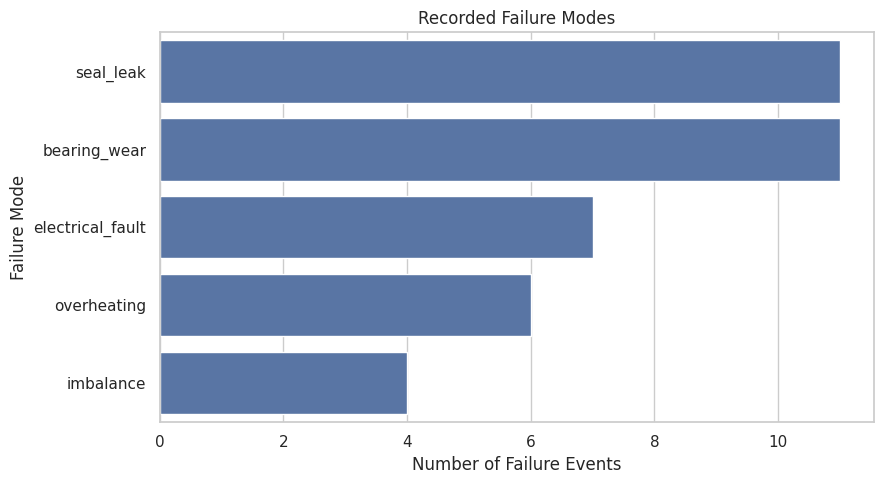

In [ ]:
failure_mode_summary = (
    failures_clean["failure_mode"]
    .value_counts()
    .rename_axis("failure_mode")
    .reset_index(name="count")
)

display(failure_mode_summary)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=failure_mode_summary,
    x="count",
    y="failure_mode"
)

plt.title("Recorded Failure Modes")
plt.xlabel("Number of Failure Events")
plt.ylabel("Failure Mode")
plt.tight_layout()
plt.show()

7.7 Downtime analysis

,asset_id,failure_count,total_downtime_hours,average_downtime_hours,asset_tag,asset_type
0,1,6,37.65,6.275000,AST-00006,Screw compressor
1,2,6,59.08,9.846667,AST-00004,Conveyor drive
2,3,7,110.79,15.827143,AST-00005,Centrifugal pump
3,4,9,115.08,12.786667,AST-00002,Induction motor
4,5,6,45.04,7.506667,AST-00003,Centrifugal pump
5,6,5,73.73,14.746000,AST-00001,Screw compressor


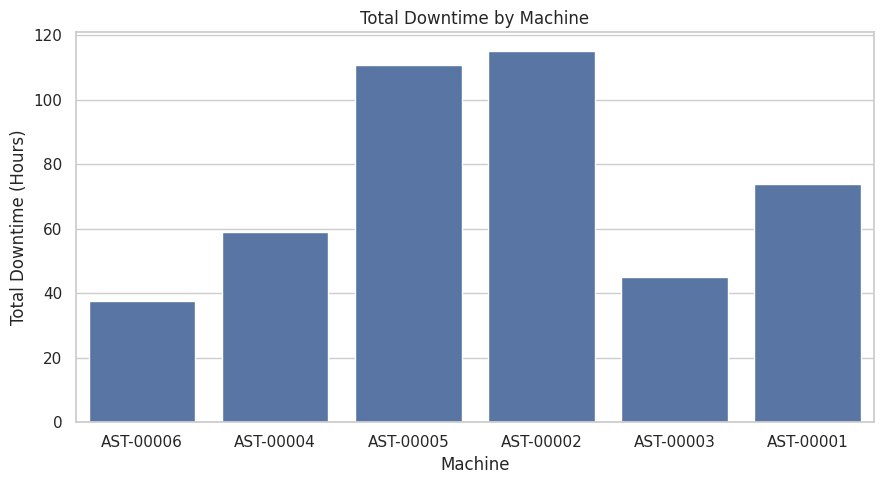

In [ ]:
downtime_by_asset = (
    failures_clean.groupby("asset_id")
    .agg(
        failure_count=("failure_id", "count"),
        total_downtime_hours=("downtime_hours", "sum"),
        average_downtime_hours=("downtime_hours", "mean")
    )
    .reset_index()
)

downtime_by_asset = downtime_by_asset.merge(
    assets_clean[["asset_id", "asset_tag", "asset_type"]],
    on="asset_id",
    how="left"
)

display(downtime_by_asset)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=downtime_by_asset,
    x="asset_tag",
    y="total_downtime_hours"
)

plt.title("Total Downtime by Machine")
plt.xlabel("Machine")
plt.ylabel("Total Downtime (Hours)")
plt.tight_layout()
plt.show()

8: Feature engineering

In [ ]:
ml_df = analysis_df.sort_values(
    ["asset_id", "recorded_at"]
).copy()

# Time-based features
ml_df["hour_of_day"] = ml_df["recorded_at"].dt.hour
ml_df["day_of_week"] = ml_df["recorded_at"].dt.dayofweek
ml_df["month"] = ml_df["recorded_at"].dt.month

# Sensor trends using previous 6 readings only
for col in available_sensor_columns:
    grouped = ml_df.groupby("asset_id")[col]

    ml_df[f"{col}_previous_6h_mean"] = grouped.transform(
        lambda s: s.shift(1).rolling(
            window=6, min_periods=2
        ).mean()
    )

    ml_df[f"{col}_previous_6h_std"] = grouped.transform(
        lambda s: s.shift(1).rolling(
            window=6, min_periods=2
        ).std()
    )

print("Feature engineering completed.")
print("New dataset shape:", ml_df.shape)

display(ml_df.head())

Feature engineering completed.
New dataset shape: (52560, 39)


,reading_id,asset_id,recorded_at,operating_mode,vibration_mm_s,bearing_temp_c,motor_current_a,discharge_pressure_bar,rotor_speed_rpm,degradation_stage,...,vibration_mm_s_previous_6h_mean,vibration_mm_s_previous_6h_std,bearing_temp_c_previous_6h_mean,bearing_temp_c_previous_6h_std,motor_current_a_previous_6h_mean,motor_current_a_previous_6h_std,discharge_pressure_bar_previous_6h_mean,discharge_pressure_bar_previous_6h_std,rotor_speed_rpm_previous_6h_mean,rotor_speed_rpm_previous_6h_std
0,1,1,2025-09-01 00:00:00,idle,1.25,42.0,17.1,5.52,1476.0,healthy,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,1,2025-09-01 01:00:00,idle,1.43,40.8,16.1,5.66,1480.0,healthy,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,1,2025-09-01 02:00:00,idle,1.50,40.2,15.9,5.62,1487.0,healthy,...,1.340000,0.127279,41.4,0.848528,16.600000,0.707107,5.590,0.098995,1478.00,2.828427
3,4,1,2025-09-01 03:00:00,normal,2.12,47.8,22.5,5.54,1484.0,healthy,...,1.393333,0.128970,41.0,0.916515,16.366667,0.642910,5.600,0.072111,1481.00,5.567764
4,5,1,2025-09-01 04:00:00,normal,2.15,46.6,24.1,5.52,1487.0,healthy,...,1.575000,0.378286,42.7,3.481379,17.900000,3.111270,5.585,0.066081,1481.75,4.787136


9: Select input features and target variable

In [ ]:
target = "failure_next_24h"

excluded_columns = [
    target,
    "reading_id",
    "asset_id",
    "site_id",
    "recorded_at",
    "commissioned_at",
    "degradation_stage",
    "rul_hours",
    "next_failure_mode",
    "failure_id",
    "failed_at",
    "restored_at",
    "failure_mode",
    "downtime_hours",
    "hours_since_last_repair",
    "work_order_id",
    "opened_at",
    "closed_at",
    "order_type",
    "labor_hours",
    "parts_cost",
    "priority"
]

X = ml_df.drop(
    columns=excluded_columns,
    errors="ignore"
)

y = ml_df[target].astype(int)

# Exclude any columns that are entirely missing.
X = X.dropna(axis=1, how="all")

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Selected input features:")
print(X.columns.tolist())

print("\nTarget variable:", target)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

print("\nTarget distribution:")
print(y.value_counts())

Selected input features:
['operating_mode', 'vibration_mm_s', 'bearing_temp_c', 'motor_current_a', 'discharge_pressure_bar', 'rotor_speed_rpm', 'asset_tag', 'asset_type', 'manufacturer', 'model_code', 'criticality', 'rated_power_kw', 'site_name', 'site_kind', 'country', 'city', 'machine_age_years', 'hour_of_day', 'day_of_week', 'month', 'vibration_mm_s_previous_6h_mean', 'vibration_mm_s_previous_6h_std', 'bearing_temp_c_previous_6h_mean', 'bearing_temp_c_previous_6h_std', 'motor_current_a_previous_6h_mean', 'motor_current_a_previous_6h_std', 'discharge_pressure_bar_previous_6h_mean', 'discharge_pressure_bar_previous_6h_std', 'rotor_speed_rpm_previous_6h_mean', 'rotor_speed_rpm_previous_6h_std']

Target variable: failure_next_24h
Numeric features: ['vibration_mm_s', 'bearing_temp_c', 'motor_current_a', 'discharge_pressure_bar', 'rotor_speed_rpm', 'rated_power_kw', 'machine_age_years', 'hour_of_day', 'day_of_week', 'month', 'vibration_mm_s_previous_6h_mean', 'vibration_mm_s_previous_6h_s

10: Split the dataset into training and testing sets

In [ ]:
ordered_indices = ml_df.sort_values(
    "recorded_at"
).index

split_position = int(len(ordered_indices) * 0.80)

train_indices = ordered_indices[:split_position]
test_indices = ordered_indices[split_position:]

X_train = X.loc[train_indices]
X_test = X.loc[test_indices]

y_train = y.loc[train_indices]
y_test = y.loc[test_indices]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining failure rate:", round(y_train.mean() * 100, 2), "%")
print("Testing failure rate:", round(y_test.mean() * 100, 2), "%")

if y_train.nunique() < 2 or y_test.nunique() < 2:
    raise ValueError(
        "The chronological split contains only one target class. "
        "Use a stratified split if appropriate for your assessment."
    )

Training records: 42048
Testing records: 10512

Training failure rate: 1.7 %
Testing failure rate: 1.75 %


11: Build and train the Random Forest model

In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


12: Evaluate model performance

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Value": [accuracy, precision, recall, f1]
})

metrics_df["Percentage"] = metrics_df["Value"] * 100

display(metrics_df.round(4))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)

,Metric,Value,Percentage
0,Accuracy,0.9825,98.2496
1,Precision,0.0000,0.0000
2,Recall,0.0000,0.0000
3,F1-score,0.0000,0.0000



Classification report:
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99     10328
     Failure       0.00      0.00      0.00       184

    accuracy                           0.98     10512
   macro avg       0.49      0.50      0.50     10512
weighted avg       0.97      0.98      0.97     10512



13: Visualize model performance

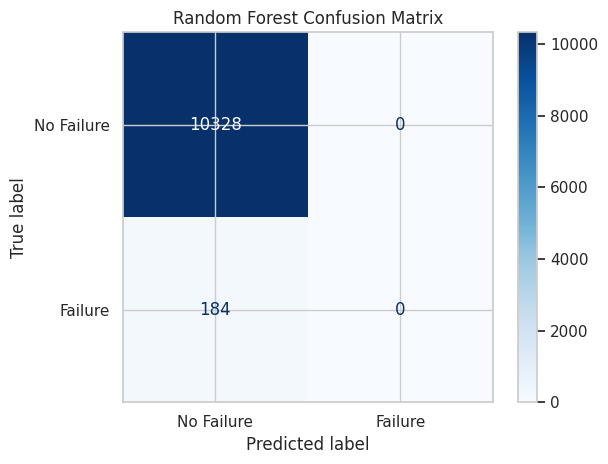

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

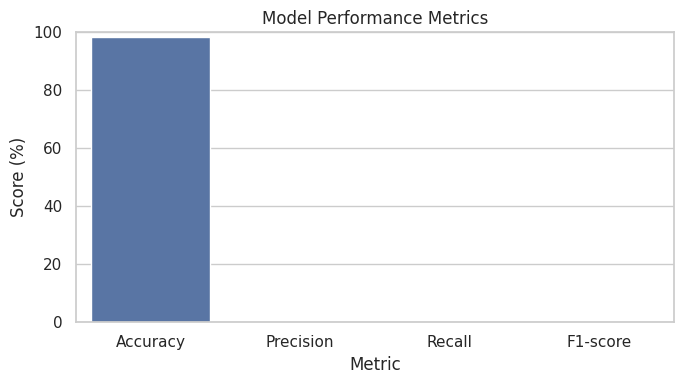

In [ ]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=metrics_df,
    x="Metric",
    y="Percentage"
)

plt.title("Model Performance Metrics")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

14: Identify important features

Top 10 important features:


,Feature,Importance
0,numeric__rotor_speed_rpm_previous_6h_std,0.107407
1,numeric__vibration_mm_s,0.095238
2,numeric__vibration_mm_s_previous_6h_mean,0.088142
3,numeric__discharge_pressure_bar_previous_6h_std,0.074338
4,numeric__discharge_pressure_bar_previous_6h_mean,0.069858
5,numeric__vibration_mm_s_previous_6h_std,0.064783
6,numeric__machine_age_years,0.053853
7,numeric__discharge_pressure_bar,0.045529
8,numeric__bearing_temp_c_previous_6h_mean,0.044678
9,numeric__motor_current_a_previous_6h_std,0.044576


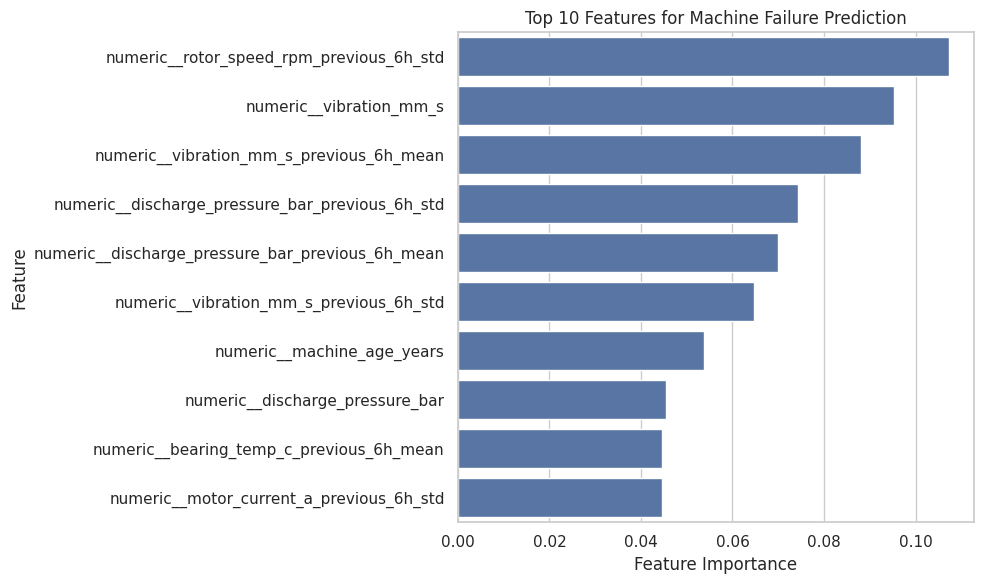

In [ ]:
fitted_preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": classifier.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("Top 10 important features:")
display(feature_importance_df.head(10))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features for Machine Failure Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

15: Generate machine maintenance recommendations

In [ ]:
prediction_results = ml_df.loc[test_indices, [
    "asset_tag",
    "asset_type",
    "recorded_at",
    "vibration_mm_s",
    "bearing_temp_c",
    "motor_current_a"
]].copy()

prediction_results["Actual_Failure"] = y_test
prediction_results["Predicted_Failure"] = y_pred
prediction_results["Failure_Probability"] = y_probability

prediction_results["Maintenance_Recommendation"] = np.select(
    [
        prediction_results["Predicted_Failure"] == 1
    ],
    [
        "Prioritize inspection"
    ],
    default="Continue routine monitoring"
)

prediction_results = prediction_results.reset_index(drop=True)

print("Maintenance prediction results:")
display(prediction_results.head(20))

print("\nPredicted failure cases:",
      int((prediction_results["Predicted_Failure"] == 1).sum()))

print("Actual failure cases:",
      int((prediction_results["Actual_Failure"] == 1).sum()))

Maintenance prediction results:


,asset_tag,asset_type,recorded_at,vibration_mm_s,bearing_temp_c,motor_current_a,Actual_Failure,Predicted_Failure,Failure_Probability,Maintenance_Recommendation
0,AST-00006,Screw compressor,2026-06-20 00:00:00,1.33,43.3,17.8,0,0,0.005000,Continue routine monitoring
1,AST-00005,Centrifugal pump,2026-06-20 00:00:00,NaN,41.9,13.6,0,0,0.014645,Continue routine monitoring
2,AST-00001,Screw compressor,2026-06-20 00:00:00,1.37,43.8,17.1,0,0,0.009915,Continue routine monitoring
3,AST-00004,Conveyor drive,2026-06-20 00:00:00,0.99,45.3,16.0,0,0,0.009915,Continue routine monitoring
4,AST-00003,Centrifugal pump,2026-06-20 00:00:00,1.34,44.3,14.0,0,0,0.014250,Continue routine monitoring
5,AST-00002,Induction motor,2026-06-20 00:00:00,0.00,26.2,0.0,0,0,0.000000,Continue routine monitoring
6,AST-00002,Induction motor,2026-06-20 01:00:00,0.00,25.2,0.0,0,0,0.000000,Continue routine monitoring
7,AST-00006,Screw compressor,2026-06-20 01:00:00,1.36,42.4,18.0,0,0,0.000000,Continue routine monitoring
8,AST-00003,Centrifugal pump,2026-06-20 01:00:00,1.35,42.8,13.4,0,0,0.004983,Continue routine monitoring
9,AST-00001,Screw compressor,2026-06-20 01:00:00,1.48,43.5,15.6,0,0,0.074630,Continue routine monitoring



Predicted failure cases: 0
Actual failure cases: 184


,asset_tag,asset_type,tested_readings,predicted_failures,average_failure_probability,predicted_failure_rate_percent
2,AST-00003,Centrifugal pump,1752,0,0.039914,0.0
4,AST-00005,Centrifugal pump,1752,0,0.035520,0.0
3,AST-00004,Conveyor drive,1752,0,0.028631,0.0
5,AST-00006,Screw compressor,1752,0,0.023250,0.0
0,AST-00001,Screw compressor,1752,0,0.021441,0.0
1,AST-00002,Induction motor,1752,0,0.021418,0.0


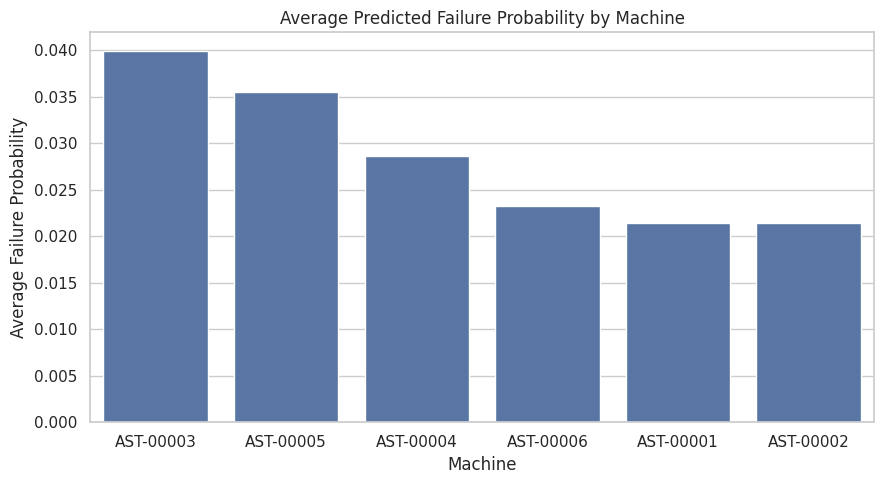

In [ ]:
machine_risk_summary = (
    prediction_results.groupby(
        ["asset_tag", "asset_type"],
        dropna=False
    )
    .agg(
        tested_readings=("Predicted_Failure", "size"),
        predicted_failures=("Predicted_Failure", "sum"),
        average_failure_probability=("Failure_Probability", "mean")
    )
    .reset_index()
)

machine_risk_summary["predicted_failure_rate_percent"] = (
    machine_risk_summary["predicted_failures"] /
    machine_risk_summary["tested_readings"] * 100
)

machine_risk_summary = machine_risk_summary.sort_values(
    "average_failure_probability",
    ascending=False
)

display(machine_risk_summary)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=machine_risk_summary,
    x="asset_tag",
    y="average_failure_probability"
)

plt.title("Average Predicted Failure Probability by Machine")
plt.xlabel("Machine")
plt.ylabel("Average Failure Probability")
plt.tight_layout()
plt.show()

16: Generate automatic key insights

In [ ]:
failure_rate = analysis_df["failure_next_24h"].mean() * 100

print("KEY INSIGHTS")
print("=" * 50)

print(
    f"1. {failure_rate:.2f}% of sensor readings are labelled "
    "as indicating a failure within the next 24 hours."
)

top_features = feature_importance_df.head(3)["Feature"].tolist()

print(
    "2. The three highest-ranked model features are: "
    + ", ".join(top_features)
    + "."
)

if not machine_risk_summary.empty:
    highest_risk = machine_risk_summary.iloc[0]

    print(
        f"3. The machine with the highest average predicted failure "
        f"probability in the test set is {highest_risk['asset_tag']} "
        f"({highest_risk['average_failure_probability']:.2%})."
    )

print("\nRECOMMENDATIONS")
print("=" * 50)

print(
    "1. Prioritize inspection of machines with repeated high-risk "
    "predictions, and verify their condition using maintenance checks."
)

print(
    "2. Monitor sensor trends and review failure and work-order "
    "history to plan preventive maintenance and reduce downtime."
)

KEY INSIGHTS
1. 1.71% of sensor readings are labelled as indicating a failure within the next 24 hours.
2. The three highest-ranked model features are: numeric__rotor_speed_rpm_previous_6h_std, numeric__vibration_mm_s, numeric__vibration_mm_s_previous_6h_mean.
3. The machine with the highest average predicted failure probability in the test set is AST-00003 (3.99%).

RECOMMENDATIONS
1. Prioritize inspection of machines with repeated high-risk predictions, and verify their condition using maintenance checks.
2. Monitor sensor trends and review failure and work-order history to plan preventive maintenance and reduce downtime.


In [ ]:
# Create work order summary
work_order_summary = (
    work_orders_clean.groupby("order_type")
    .agg(
        work_order_count=("work_order_id", "count"),
        total_labor_hours=("labor_hours", "sum"),
        total_parts_cost=("parts_cost", "sum")
    )
    .reset_index()
)

print("Work order summary created successfully!")
display(work_order_summary)

Work order summary created successfully!


,order_type,work_order_count,total_labor_hours,total_parts_cost
0,corrective,39,635.7,54277.23
1,preventive,24,129.9,3400.26


17: Export all results to Excel

In [ ]:
output_path = "/content/Machine_Maintenance_Insight_Report.xlsx"

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:

    # Cleaned and analyzed datasets
    analysis_df.to_excel(
        writer,
        sheet_name="Cleaned_Data",
        index=False
    )

    assets_clean.to_excel(
        writer,
        sheet_name="Machines",
        index=False
    )

    failures_clean.to_excel(
        writer,
        sheet_name="Failure_Events",
        index=False
    )

    work_orders_clean.to_excel(
        writer,
        sheet_name="Work_Orders",
        index=False
    )

    # EDA outputs
    machine_type_summary.to_excel(
        writer,
        sheet_name="Machine_Type_EDA",
        index=False
    )

    failure_mode_summary.to_excel(
        writer,
        sheet_name="Failure_Modes",
        index=False
    )

    downtime_by_asset.to_excel(
        writer,
        sheet_name="Downtime_Analysis",
        index=False
    )

    work_order_summary.to_excel(
        writer,
        sheet_name="Work_Order_Analysis",
        index=False
    )

    # ML outputs
    metrics_df.to_excel(
        writer,
        sheet_name="Model_Metrics",
        index=False
    )

    feature_importance_df.to_excel(
        writer,
        sheet_name="Feature_Importance",
        index=False
    )

    prediction_results.to_excel(
        writer,
        sheet_name="Predictions",
        index=False
    )

    machine_risk_summary.to_excel(
        writer,
        sheet_name="Maintenance_Priority",
        index=False
    )

    # Summary sheet
    summary_df = pd.DataFrame({
        "Item": [
            "Project",
            "Dataset",
            "Sensor records analyzed",
            "Unique machines",
            "Failure events recorded",
            "Work orders recorded",
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score"
        ],
        "Value": [
            "Machine Maintenance Insight",
            "Factory Sensors with Failure Labels",
            len(analysis_df),
            analysis_df["asset_id"].nunique(),
            len(failures_clean),
            len(work_orders_clean),
            "Random Forest Classifier",
            round(accuracy, 4),
            round(precision, 4),
            round(recall, 4),
            round(f1, 4)
        ]
    })

    summary_df.to_excel(
        writer,
        sheet_name="Summary",
        index=False
    )

    # Format worksheet headers and column widths.
    for worksheet in writer.sheets.values():
        worksheet.freeze_panes = "A2"
        worksheet.auto_filter.ref = worksheet.dimensions

        for column_cells in worksheet.columns:
            max_length = max(
                len(str(cell.value)) if cell.value is not None else 0
                for cell in list(column_cells)[:200]
            )

            worksheet.column_dimensions[
                column_cells[0].column_letter
            ].width = min(max_length + 2, 32)

print("Excel report created successfully!")
print("Saved at:", output_path)

Excel report created successfully!
Saved at: /content/Machine_Maintenance_Insight_Report.xlsx


In [ ]:
files.download(
    "/content/Machine_Maintenance_Insight_Report.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Final Verification

In [ ]:
print("=" * 55)
print("MACHINE MAINTENANCE INSIGHT — FINAL REPORT")
print("=" * 55)

print(f"Sensor records analyzed : {len(analysis_df):,}")
print(f"Unique machines         : {analysis_df['asset_id'].nunique()}")
print(f"Failure events          : {len(failures_clean)}")
print(f"Work orders             : {len(work_orders_clean)}")
print(f"Training records        : {len(X_train):,}")
print(f"Testing records         : {len(X_test):,}")
print(f"Accuracy                : {accuracy:.4f}")
print(f"Precision               : {precision:.4f}")
print(f"Recall                  : {recall:.4f}")
print(f"F1-score                : {f1:.4f}")

print("\nTop 5 important features:")
display(feature_importance_df.head(5))

print("\nTop maintenance priorities:")
display(machine_risk_summary.head(5))

print("\nExcel report:", output_path)
print("PRACTICAL COMPLETED")

MACHINE MAINTENANCE INSIGHT — FINAL REPORT
Sensor records analyzed : 52,560
Unique machines         : 6
Failure events          : 39
Work orders             : 63
Training records        : 42,048
Testing records         : 10,512
Accuracy                : 0.9825
Precision               : 0.0000
Recall                  : 0.0000
F1-score                : 0.0000

Top 5 important features:


,Feature,Importance
0,numeric__rotor_speed_rpm_previous_6h_std,0.107407
1,numeric__vibration_mm_s,0.095238
2,numeric__vibration_mm_s_previous_6h_mean,0.088142
3,numeric__discharge_pressure_bar_previous_6h_std,0.074338
4,numeric__discharge_pressure_bar_previous_6h_mean,0.069858



Top maintenance priorities:


,asset_tag,asset_type,tested_readings,predicted_failures,average_failure_probability,predicted_failure_rate_percent
2,AST-00003,Centrifugal pump,1752,0,0.039914,0.0
4,AST-00005,Centrifugal pump,1752,0,0.035520,0.0
3,AST-00004,Conveyor drive,1752,0,0.028631,0.0
5,AST-00006,Screw compressor,1752,0,0.023250,0.0
0,AST-00001,Screw compressor,1752,0,0.021441,0.0



Excel report: /content/Machine_Maintenance_Insight_Report.xlsx
PRACTICAL COMPLETED
